<a href="https://colab.research.google.com/github/ludmiladenise/DataScientist/blob/main/EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files


In [8]:
df = pd.read_csv('/content/dataset_limpio.csv')

df.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [9]:
df.columns

Index(['PatientId', 'AppointmentID', 'Gender', 'ScheduledDay',
       'AppointmentDay', 'Age', 'Neighbourhood', 'Scholarship', 'Hipertension',
       'Diabetes', 'Alcoholism', 'Handcap', 'SMS_received', 'No-show'],
      dtype='object')

In [20]:
df = df.drop(columns=['PatientId', 'AppointmentID'])

In [32]:
df.to_csv('dataset_limpio.csv', index=False)

In [33]:
from google.colab import files
files.download('dataset_limpio.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype              
---  ------          --------------   -----              
 0   Gender          110527 non-null  object             
 1   ScheduledDay    110527 non-null  datetime64[ns, UTC]
 2   AppointmentDay  110527 non-null  datetime64[ns, UTC]
 3   Age             110527 non-null  int64              
 4   Neighbourhood   110527 non-null  object             
 5   Scholarship     110527 non-null  int64              
 6   Hipertension    110527 non-null  int64              
 7   Diabetes        110527 non-null  int64              
 8   Alcoholism      110527 non-null  int64              
 9   Handcap         110527 non-null  int64              
 10  SMS_received    110527 non-null  int64              
 11  No-show         110527 non-null  object             
 12  WaitingDays     110527 non-null  int64              
dtypes: datetime64[

In [35]:
df.isnull().sum()

,0
Gender,0
ScheduledDay,0
AppointmentDay,0
Age,0
Neighbourhood,0
Scholarship,0
Hipertension,0
Diabetes,0
Alcoholism,0
Handcap,0


In [36]:
sns.set_theme(style="whitegrid", palette="deep")

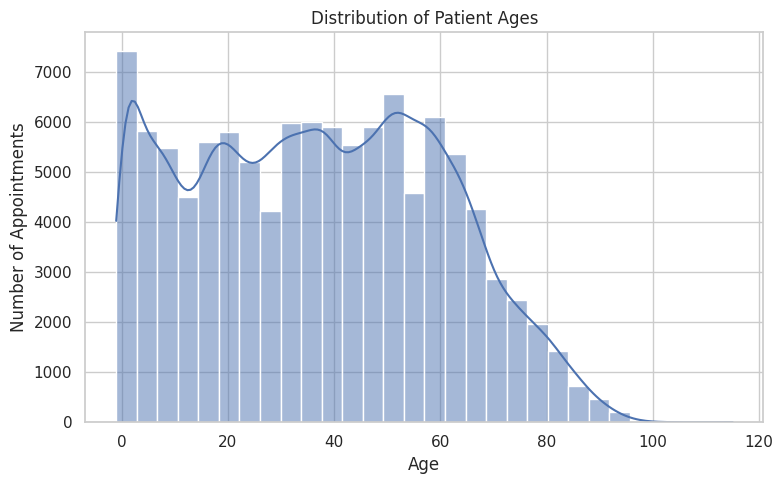

In [37]:
plt.figure(figsize=(8,5))

sns.histplot(data=df, x='Age', bins=30, kde=True)

plt.title('Distribution of Patient Ages')
plt.xlabel('Age')
plt.ylabel('Number of Appointments')

plt.tight_layout()
plt.show()

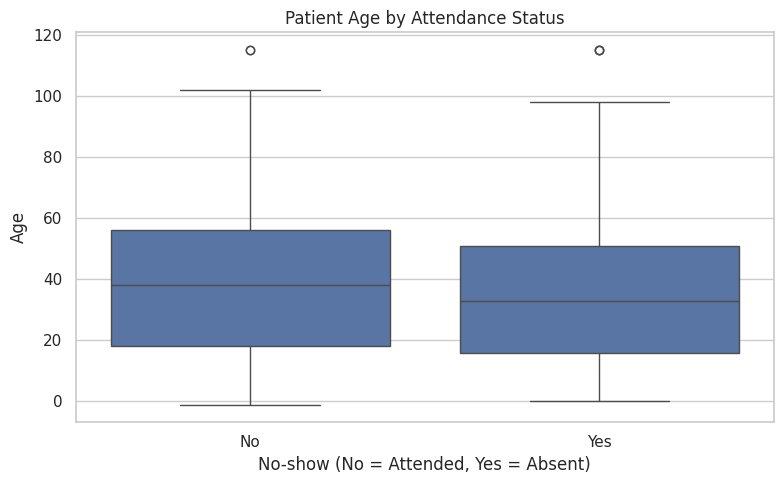

In [38]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x='No-show', y='Age')

plt.title('Patient Age by Attendance Status')
plt.xlabel('No-show (No = Attended, Yes = Absent)')
plt.ylabel('Age')

plt.tight_layout()
plt.show()

In [39]:
df['ScheduledDay'] = pd.to_datetime(df['ScheduledDay'])
df['AppointmentDay'] = pd.to_datetime(df['AppointmentDay'])

df['WaitingDays'] = (
    df['AppointmentDay'].dt.normalize() -
    df['ScheduledDay'].dt.normalize()
).dt.days

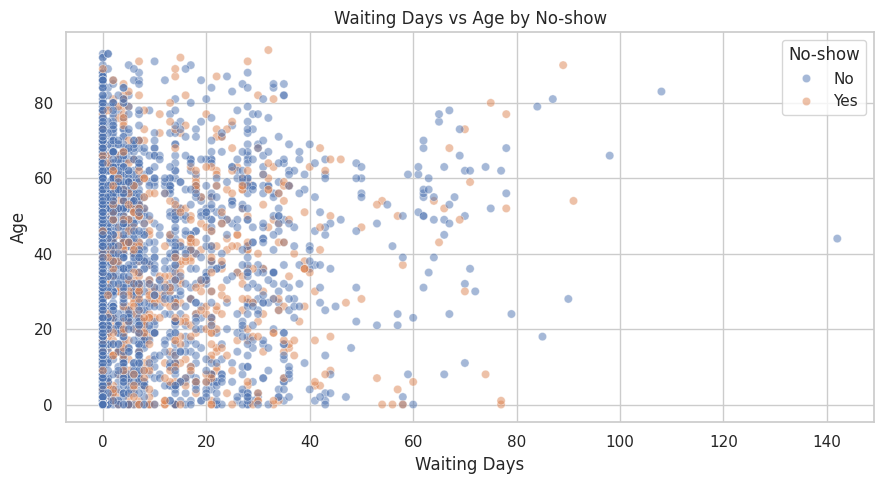

In [40]:
plt.figure(figsize=(9,5))

sns.scatterplot(
    data=df.sample(min(3000, len(df)), random_state=42),
    x='WaitingDays',
    y='Age',
    hue='No-show',
    alpha=0.5
)

plt.title('Waiting Days vs Age by No-show')
plt.xlabel('Waiting Days')
plt.ylabel('Age')

plt.tight_layout()
plt.show()

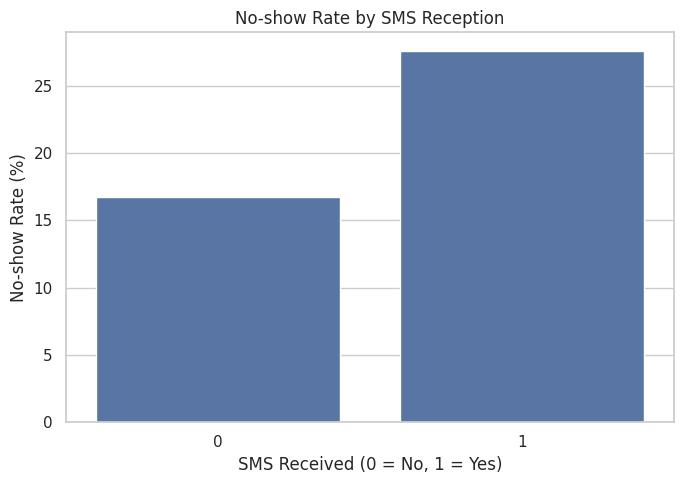

In [41]:
tasa_sms = df.groupby('SMS_received')['No-show'].apply(
    lambda x: (x == 'Yes').mean() * 100
).reset_index(name='Porcentaje')

plt.figure(figsize=(7,5))

sns.barplot(data=tasa_sms, x='SMS_received', y='Porcentaje')

plt.title('No-show Rate by SMS Reception')
plt.xlabel('SMS Received (0 = No, 1 = Yes)')
plt.ylabel('No-show Rate (%)')

plt.tight_layout()
plt.show()

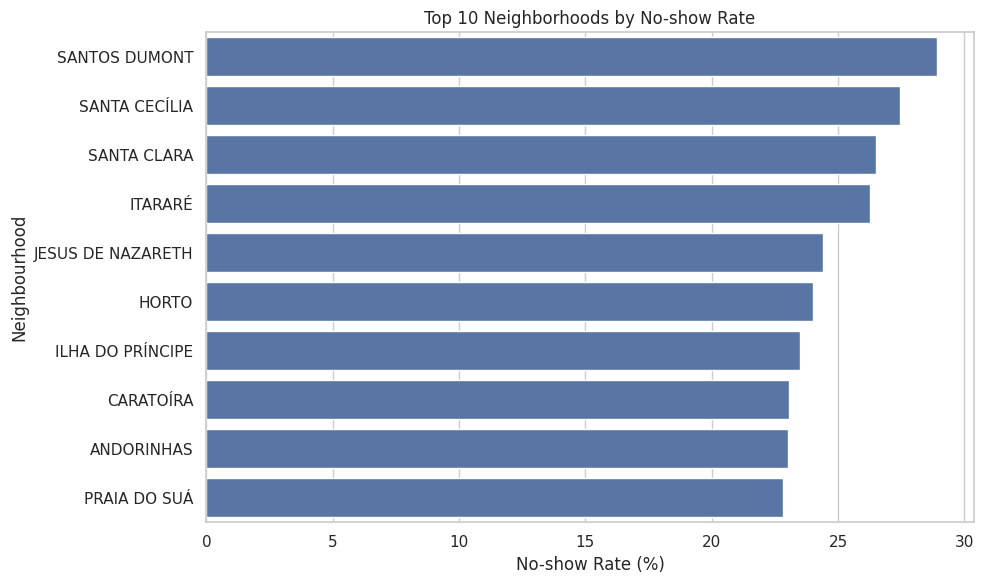

In [42]:
tasa_barrio = (
    df.groupby('Neighbourhood')
    .agg(
        Total=('No-show', 'size'),
        Inasistencias=('No-show', lambda x: (x == 'Yes').sum())
    )
)

tasa_barrio['Porcentaje'] = (
    tasa_barrio['Inasistencias'] / tasa_barrio['Total'] * 100
)

# Barrios con al menos 100 turnos
tasa_barrio = tasa_barrio[tasa_barrio['Total'] >= 100]

top_barrios = tasa_barrio.nlargest(10, 'Porcentaje').reset_index()

plt.figure(figsize=(10,6))

sns.barplot(
    data=top_barrios,
    x='Porcentaje',
    y='Neighbourhood'
)

plt.title('Top 10 Neighborhoods by No-show Rate')
plt.xlabel('No-show Rate (%)')
plt.ylabel('Neighbourhood')

plt.tight_layout()
plt.show()

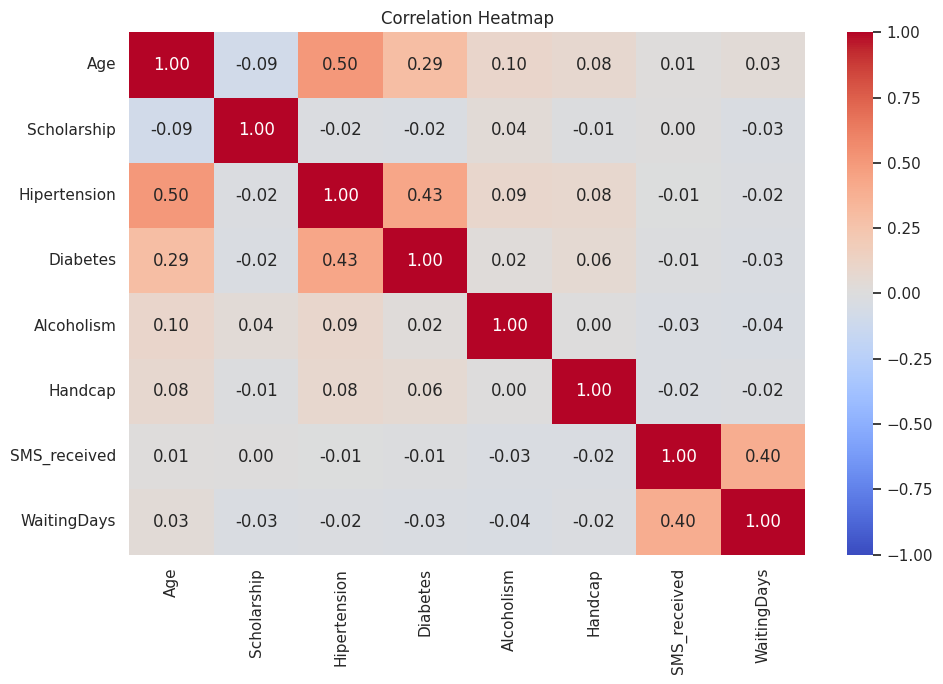

In [43]:
columnas = [
    'Age',
    'Scholarship',
    'Hipertension',
    'Diabetes',
    'Alcoholism',
    'Handcap',
    'SMS_received',
    'WaitingDays'
]

corr_df = df[columnas].corr()

plt.figure(figsize=(10,7))

sns.heatmap(
    corr_df,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap')

plt.tight_layout()
plt.show()